In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una instalación industrial termina con las **pruebas de presión y la inspección reglamentaria** (actividad I), exigidas por la normativa de seguridad antes de la puesta en servicio. El cuadro de prelaciones, las duraciones (semanas), las duraciones mínimas alcanzables y el coste unitario de reducción (k€ por semana) se adjuntan; I no se puede acortar.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 2       , 2           , 0     ),
    ('B'     , '---'      , 4       , 1           , 2     ),
    ('C'     , 'A,B'      , 3       , 2           , 6     ),
    ('D'     , 'A'        , 2       , 2           , 0     ),
    ('E'     , 'A'        , 3       , 1           , 5     ),
    ('F'     , 'D'        , 7       , 7           , 0     ),
    ('G'     , 'C,D,E'    , 3       , 1           , 1     ),
    ('H'     , 'E'        , 8       , 6           , 3     ),
    ('I'     , 'F,G,H'    , 2       , 2           , np.inf),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,2,2,0.0
B,---,4,1,2.0
C,"A,B",3,2,6.0
D,A,2,2,0.0
E,A,3,1,5.0
F,D,7,7,0.0
G,"C,D,E",3,1,1.0
H,E,8,6,3.0
I,"F,G,H",2,2,inf


El cliente exige adelantar la puesta en servicio **2 semanas**. En una reunión, el director de operaciones propone lo siguiente.

> **De: Director de operaciones**
> Lo más barato es quitar I: son 2 semanas a coste cero. Las pruebas las hacemos «en marcha» el primer mes de servicio, que en la práctica es lo mismo, y el inspector firma después. Lo otro es pagar reducciones.

Según el responsable de calidad, con probabilidad 10% la inspección detecta un defecto que, si se pusiera en servicio sin corregir, costaría 200 k€ (parada, reparación y daños).

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C7 — Cumplimiento de la ley y de las normas de seguridad.** El proyecto no puede planificarse incumpliendo una norma legal o de seguridad aunque salga más barato o más rápido; una actividad exigida por una norma no es una opción de compresión. *(cf. Código Ético del PMI, 2.3.1 y 2.2.1; ICB4, Perspectiva 3 «cumplimiento, estándares y regulaciones»; PMBOK 8, principio de calidad integrada.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el coste mínimo de adelantar 2 semanas acortando actividades (sin tocar la inspección) y las actividades que se acortan en cada paso.  "
pregunta_2 = "2. (A) Calcule el coste esperado de poner en servicio sin la inspección (probabilidad del defecto por su coste) y compárelo con el coste de la reducción legítima. ¿Qué «ahorra» de verdad la propuesta?  "
pregunta_3 = "3. (B) Según el criterio de referencia, ¿es la supresión de la inspección una opción de compresión? ¿Qué distingue comprimir el cronograma de recortar el alcance?  "
pregunta_4 = "4. (C) ¿Qué responde al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el coste mínimo de adelantar 2 semanas acortando actividades (sin tocar la inspección) y las actividades que se acortan en cada paso.  

2. (A) Calcule el coste esperado de poner en servicio sin la inspección (probabilidad del defecto por su coste) y compárelo con el coste de la reducción legítima. ¿Qué «ahorra» de verdad la propuesta?  

3. (B) Según el criterio de referencia, ¿es la supresión de la inspección una opción de compresión? ¿Qué distingue comprimir el cronograma de recortar el alcance?  

4. (C) ¿Qué responde al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
inspeccion, semanas_pedidas, p_defecto, coste_defecto = 'I', 2, 0.1, 200
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

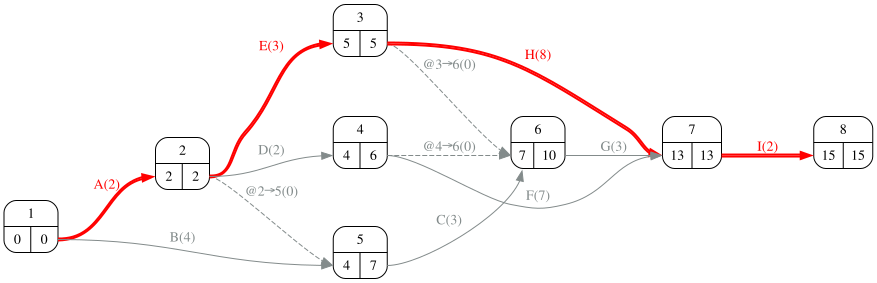

In [8]:
#| fig-cap: "Grafo PERT con el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Cálculo de los tiempos tempranos y tardíos de los sucesos paso a paso (avance con los botones):

In [7]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

**Tiempos tempranos (hacia delante)**

- $t_{1} = 0$
- $t_{2} = 0+2 = 2$ &nbsp; (A)
- $t_{3} = 2+3 = 5$ &nbsp; (E)
- $t_{4} = 2+2 = 4$ &nbsp; (D)
- $t_{5} = \max\{2+0,\ 0+4\} = 4$ &nbsp; (@2→5, B)
- $t_{6} = \max\{5+0,\ 4+0,\ 4+3\} = 7$ &nbsp; (@3→6, @4→6, C)
- $t_{7} = \max\{4+7,\ 7+3,\ 5+8\} = 13$ &nbsp; (F, G, H)
- $t_{8} = 13+2 = 15$ &nbsp; (I)

**Tiempos tardíos (hacia atrás)**

- $t_{8}^{*} = t_{8} = 15$
- $t_{7}^{*} = 15-2 = 13$ &nbsp; (I)
- $t_{6}^{*} = 13-3 = 10$ &nbsp; (G)
- $t_{5}^{*} = 10-3 = 7$ &nbsp; (C)
- $t_{4}^{*} = \min\{10-0,\ 13-7\} = 6$ &nbsp; (@4→6, F)
- $t_{3}^{*} = \min\{10-0,\ 13-8\} = 5$ &nbsp; (@3→6, H)
- $t_{2}^{*} = \min\{7-0,\ 6-2,\ 5-3\} = 2$ &nbsp; (@2→5, D, E)
- $t_{1}^{*} = \min\{2-2,\ 7-4\} = 0$ &nbsp; (A, B)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Obtenga con el algoritmo de Ackoff-Sasieni el coste mínimo de adelantar 2 semanas acortando actividades (sin tocar la inspección) y las actividades que se acortan en cada paso.  

In [10]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=semanas_pedidas, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2
Route_1,0.0,,6.0,,,,1.0,,inf,10.0,10.0,10.0
Route_2,0.0,,,0.0,,0.0,,,inf,13.0,13.0,13.0
Route_3,0.0,,,0.0,,,1.0,,inf,9.0,9.0,9.0
Route_4,0.0,,,,5.0,,1.0,,inf,10.0,10.0,10.0
Route_5,0.0,,,,5.0,,,3.0,inf,15.0,14.0,13.0
Route_6,,2.0,6.0,,,,1.0,,inf,12.0,12.0,12.0
0,0.0,3.0,1.0,0.0,2.0,0.0,2.0,2.0,0.0,,,
1,0.0,3.0,1.0,0.0,2.0,0.0,2.0,1.0,0.0,,,
2,0.0,3.0,1.0,0.0,2.0,0.0,2.0,0.0,0.0,,,


In [11]:
#| tbl-cap: "Opciones consideradas en cada paso"
#| label: tbl-ackoffPaso
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,15,Route_5,H (3); E (5),H,3.0
2,14,Route_5,H (3); E (5),H,3.0


In [12]:
coste_reduccion = float(sum(datos_proyecto.loc[acts, 'ucr'].sum() for acts in pasos.values()))
duracion_reducida = int(proyecto.duration(duraciones_reducidas))
Markdown(f'''Adelantar {semanas_pedidas} semanas acortando actividades cuesta **{coste_reduccion:.0f} k€** (de {duracion} a {duracion_reducida} semanas); pasos: ''' + '; '.join(', '.join(a) for a in pasos.values()) + '.')

Adelantar 2 semanas acortando actividades cuesta **6 k€** (de 15 a 13 semanas); pasos: H; H.

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste esperado de poner en servicio sin la inspección (probabilidad del defecto por su coste) y compárelo con el coste de la reducción legítima. ¿Qué «ahorra» de verdad la propuesta?  

In [14]:
coste_esperado_sin_inspeccion = p_defecto * coste_defecto
Markdown(f'''Sin la inspección, el coste esperado del defecto es {p_defecto:.0%} × {coste_defecto} = **{coste_esperado_sin_inspeccion:.0f} k€**, frente a los {coste_reduccion:.0f} k€ de la reducción legítima. La propuesta no ahorra: traslada un coste mayor, incierto y a cargo de otros (usuarios, aseguradora, inspector) a cambio de un ahorro cierto y pequeño.''')

Sin la inspección, el coste esperado del defecto es 10% × 200 = **20 k€**, frente a los 6 k€ de la reducción legítima. La propuesta no ahorra: traslada un coste mayor, incierto y a cargo de otros (usuarios, aseguradora, inspector) a cambio de un ahorro cierto y pequeño.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según el criterio de referencia, ¿es la supresión de la inspección una opción de compresión? ¿Qué distingue comprimir el cronograma de recortar el alcance?  

**C7.** I está exigida por una norma de seguridad: no es una opción de compresión, de modo que no entra en la tabla de Ackoff (por eso su coste de reducción es infinito y no «cero»). Comprimir el cronograma es hacer el **mismo alcance** en menos tiempo pagando por ello (reducción de duraciones, más recursos, solapes); quitar una actividad es **recortar el alcance**, y cuando la actividad es un requisito legal, incumplir la norma. Hacer las pruebas «en marcha» no es lo mismo: la norma exige la inspección antes de la puesta en servicio, y el inspector que firma después firma algo que no ha visto. La respuesta no depende del cálculo del apartado 2; el cálculo sólo muestra que, además, es mal negocio.

In [16]:
preguntas_test = [
    ('Suprimir una actividad exigida por una norma para acortar el proyecto es…', ['recortar el alcance e incumplir la norma (C7)', 'una opción de compresión más', 'legítimo si el cliente lo pide', 'una reducción a coste cero'],
     'Comprimir es hacer el mismo alcance en menos tiempo; esto cambia el alcance y viola la norma.'),
    ('En el algoritmo de Ackoff-Sasieni una actividad que no puede acortarse se modela con…', ['coste unitario de reducción infinito', 'coste cero', 'duración mínima cero', 'una ficticia'],
     'Infinito la saca de las opciones; cero la convertiría en la primera elegida.'),
    ('El coste esperado de poner en servicio sin inspección se calcula como…', ['probabilidad del defecto por su coste', 'coste del defecto', 'coste de la inspección', 'semanas ahorradas por el CUR'],
     'Es un valor esperado: p · K.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — inspección suprimida')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — inspección suprimida

::Ética 19 — inspección suprimida P1::Suprimir una actividad exigida por una norma para acortar el proyecto es… {=recortar el alcance e incumplir la norma (C7) ~una opción de compresión más ~legítimo si el cliente lo pide ~una reducción a coste cero ####Comprimir es hacer el mismo alcance en menos tiempo; esto cambia el alcance y viola la norma.}

::Ética 19 — inspección suprimida P2::En el algoritmo de Ackoff-Sasieni una actividad que no puede acortarse se modela con… {~una ficticia =coste unitario de reducción infinito ~duración mínima cero ~coste cero ####Infinito la saca de las opciones; cero la convertiría en la primera elegida.}

::Ética 19 — inspección suprimida P3::El coste esperado de poner en servicio sin inspección se calcula como… {~semanas ahorradas por el CUR =probabilidad del defecto por su coste ~coste del defecto ~coste de la inspección ####Es un valor esperado: p · K.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué responde al director de operaciones y qué ofrece al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de operaciones: la inspección no está en la tabla de opciones; la tabla real es «2 semanas por 6 k€» con las actividades del apartado 1, o menos semanas por menos dinero. Al cliente: la oferta de reducción con su precio y, si quiere, la curva coste-semanas; la puesta en servicio sigue exigiendo la inspección. Prueba de publicidad: ¿explicaría al inspector, o a los usuarios, que las pruebas se hicieron después de arrancar?